In [1]:
!pip install -q opencv-contrib-python scikit-learn pandas matplotlib

In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [4]:
uploaded = files.upload()

Saving processed.zip to processed.zip


In [5]:
!unzip -q processed.zip -d dataset

In [6]:
!find dataset -maxdepth 3 -type f | head -20

dataset/processed/pastel/PAS_16_processed.png
dataset/processed/pastel/PAS_12_processed.png
dataset/processed/pastel/PAS_23_processed.png
dataset/processed/pastel/PAS_08_processed.png
dataset/processed/pastel/PAS_24_processed.png
dataset/processed/pastel/PAS_21_processed.png
dataset/processed/pastel/PAS_17_processed.png
dataset/processed/pastel/PAS_10_processed.png
dataset/processed/pastel/PAS_19_processed.png
dataset/processed/pastel/PAS_15_processed.png
dataset/processed/pastel/PAS_02_processed.png
dataset/processed/pastel/PAS_09_processed.png
dataset/processed/pastel/PAS_14_processed.png
dataset/processed/pastel/PAS_01_processed.png
dataset/processed/pastel/PAS_25_processed.png
dataset/processed/pastel/PAS_07_processed.png
dataset/processed/pastel/PAS_18_processed.png
dataset/processed/pastel/PAS_13_processed.png
dataset/processed/pastel/PAS_04_processed.png
dataset/processed/pastel/PAS_20_processed.png


In [7]:
DATASET_PATH = "dataset/processed"

classes = ["oil", "watercolour", "ink", "pastel", "graphite"]

images = []
labels = []

class_to_label = {
    "oil": 0,
    "watercolour": 1,
    "ink": 2,
    "pastel": 3,
    "graphite": 4
}

for class_name in classes:

    class_path = os.path.join(DATASET_PATH, class_name)

    for filename in os.listdir(class_path):

        file_path = os.path.join(class_path, filename)

        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):

            img = cv2.imread(file_path)

            if img is None:
                continue

            # Convert to grayscale for Harris/SIFT
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

            images.append(gray)
            labels.append(class_to_label[class_name])

images = np.array(images)
labels = np.array(labels)

print("Total images:", len(images))
print("Image shape:", images[0].shape)

for class_name, label in class_to_label.items():
    print(
        class_name,
        ":",
        np.sum(labels == label)
    )

Total images: 125
Image shape: (256, 256)
oil : 25
watercolour : 25
ink : 25
pastel : 25
graphite : 25


In [9]:
indices = np.arange(len(images))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

X_train_images = images[train_idx]
X_test_images = images[test_idx]

y_train = labels[train_idx]
y_test = labels[test_idx]

print("Training images:", len(X_train_images))
print("Testing images:", len(X_test_images))

Training images: 100
Testing images: 25


# Harris Corner

In [10]:
def extract_harris_features(
    img,
    block_size=2,
    ksize=3,
    k=0.04,
    num_top_corners=20
):

    # Ensure uint8
    if img.dtype != np.uint8:
        img = img.astype(np.uint8)

    # Harris corner response
    harris_response = cv2.cornerHarris(
        np.float32(img),
        block_size,
        ksize,
        k
    )

    # Threshold strong corners
    threshold = 0.01 * harris_response.max()

    corner_mask = harris_response > threshold

    corner_responses = harris_response[corner_mask]

    # -------------------------
    # Feature 1: Statistics
    # -------------------------

    num_corners = np.sum(corner_mask)

    mean_response = (
        np.mean(corner_responses)
        if len(corner_responses) > 0
        else 0
    )

    std_response = (
        np.std(corner_responses)
        if len(corner_responses) > 0
        else 0
    )

    max_response = harris_response.max()

    # -------------------------
    # Feature 2: Top corner coordinates
    # -------------------------

    y, x = np.where(corner_mask)

    if len(x) > 0:

        responses = harris_response[y, x]

        sorted_indices = np.argsort(responses)[::-1]

        sorted_indices = sorted_indices[:num_top_corners]

        top_x = x[sorted_indices]
        top_y = y[sorted_indices]

    else:

        top_x = np.array([])
        top_y = np.array([])

    # Pad if fewer corners
    if len(top_x) < num_top_corners:

        pad_length = num_top_corners - len(top_x)

        top_x = np.pad(
            top_x,
            (0, pad_length),
            constant_values=0
        )

        top_y = np.pad(
            top_y,
            (0, pad_length),
            constant_values=0
        )

    # -------------------------
    # Feature 3: Intensity histogram
    # -------------------------

    pixels = (
        img[corner_mask]
        if num_corners > 0
        else np.array([0])
    )

    hist, _ = np.histogram(
        pixels,
        bins=8,
        range=(0, 256)
    )

    hist = hist / (np.sum(hist) + 1e-7)

    # Combine everything
    features = np.hstack([
        num_corners,
        mean_response,
        std_response,
        max_response,
        top_x,
        top_y,
        hist
    ])

    return features

In [11]:
print("Extracting Harris features...")

X_train_harris = np.array([
    extract_harris_features(img)
    for img in X_train_images
])

X_test_harris = np.array([
    extract_harris_features(img)
    for img in X_test_images
])

print("Training feature shape:", X_train_harris.shape)
print("Testing feature shape:", X_test_harris.shape)

Extracting Harris features...
Training feature shape: (100, 52)
Testing feature shape: (25, 52)


In [12]:
harris_scaler = StandardScaler()

X_train_harris_scaled = harris_scaler.fit_transform(
    X_train_harris
)

X_test_harris_scaled = harris_scaler.transform(
    X_test_harris
)

In [13]:
harris_svm = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    random_state=42
)

harris_svm.fit(
    X_train_harris_scaled,
    y_train
)

harris_svm_predictions = harris_svm.predict(
    X_test_harris_scaled
)

harris_svm_accuracy = accuracy_score(
    y_test,
    harris_svm_predictions
)

print(
    "Harris + SVM Accuracy:",
    round(harris_svm_accuracy * 100, 2),
    "%"
)

Harris + SVM Accuracy: 24.0 %


# Harris + Cosine Similarity

In [14]:
def cosine_similarity(a, b):

    denominator = (
        np.linalg.norm(a)
        * np.linalg.norm(b)
    )

    if denominator == 0:
        return 0

    return np.dot(a, b) / denominator

In [15]:
harris_class_centroids = {}

for class_label in np.unique(y_train):

    class_features = X_train_harris_scaled[
        y_train == class_label
    ]

    centroid = np.mean(
        class_features,
        axis=0
    )

    harris_class_centroids[class_label] = centroid

In [16]:
harris_cosine_predictions = []

for feature in X_test_harris_scaled:

    similarities = {}

    for class_label, centroid in harris_class_centroids.items():

        similarity = cosine_similarity(
            feature,
            centroid
        )

        similarities[class_label] = similarity

    predicted_class = max(
        similarities,
        key=similarities.get
    )

    harris_cosine_predictions.append(
        predicted_class
    )

harris_cosine_predictions = np.array(
    harris_cosine_predictions
)

harris_cosine_accuracy = accuracy_score(
    y_test,
    harris_cosine_predictions
)

print(
    "Harris + Cosine Similarity Accuracy:",
    round(harris_cosine_accuracy * 100, 2),
    "%"
)

Harris + Cosine Similarity Accuracy: 24.0 %


# Sift

In [17]:
sift = cv2.SIFT_create()

def extract_sift_descriptors(images):

    descriptors_list = []

    for img in images:

        keypoints, descriptors = sift.detectAndCompute(
            img,
            None
        )

        if descriptors is None:
            descriptors_list.append(
                np.empty((0, 128))
            )
        else:
            descriptors_list.append(
                descriptors
            )

    return descriptors_list

In [18]:
print("Extracting SIFT descriptors...")

train_descriptors = extract_sift_descriptors(
    X_train_images
)

test_descriptors = extract_sift_descriptors(
    X_test_images
)

print("SIFT extraction complete.")

Extracting SIFT descriptors...
SIFT extraction complete.


In [19]:
all_train_descriptors = np.vstack([
    desc
    for desc in train_descriptors
    if len(desc) > 0
])

print(
    "Total training SIFT descriptors:",
    all_train_descriptors.shape
)

Total training SIFT descriptors: (26653, 128)


In [20]:
VOCAB_SIZE = 50

kmeans = KMeans(
    n_clusters=VOCAB_SIZE,
    random_state=42,
    n_init=10
)

kmeans.fit(all_train_descriptors)

print("BoVW vocabulary created.")

BoVW vocabulary created.


In [21]:
def build_bovw_features(
    descriptors_list,
    kmeans_model,
    vocab_size
):

    features = []

    for descriptors in descriptors_list:

        histogram = np.zeros(
            vocab_size
        )

        if descriptors is not None and len(descriptors) > 0:

            visual_words = kmeans_model.predict(
                descriptors
            )

            histogram, _ = np.histogram(
                visual_words,
                bins=np.arange(vocab_size + 1)
            )

        # L2 normalization
        norm = np.linalg.norm(histogram)

        if norm > 0:
            histogram = histogram / norm

        features.append(histogram)

    return np.array(features)

In [22]:
X_train_sift = build_bovw_features(
    train_descriptors,
    kmeans,
    VOCAB_SIZE
)

X_test_sift = build_bovw_features(
    test_descriptors,
    kmeans,
    VOCAB_SIZE
)

print("Training SIFT feature shape:", X_train_sift.shape)
print("Testing SIFT feature shape:", X_test_sift.shape)

Training SIFT feature shape: (100, 50)
Testing SIFT feature shape: (25, 50)


In [23]:
sift_scaler = StandardScaler()

X_train_sift_scaled = sift_scaler.fit_transform(
    X_train_sift
)

X_test_sift_scaled = sift_scaler.transform(
    X_test_sift
)

In [24]:
sift_svm = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    random_state=42
)

sift_svm.fit(
    X_train_sift_scaled,
    y_train
)

sift_svm_predictions = sift_svm.predict(
    X_test_sift_scaled
)

sift_svm_accuracy = accuracy_score(
    y_test,
    sift_svm_predictions
)

print(
    "SIFT + SVM Accuracy:",
    round(sift_svm_accuracy * 100, 2),
    "%"
)

SIFT + SVM Accuracy: 56.0 %


# Sift + Cosine Similarity

In [25]:
sift_class_centroids = {}

for class_label in np.unique(y_train):

    class_features = X_train_sift_scaled[
        y_train == class_label
    ]

    centroid = np.mean(
        class_features,
        axis=0
    )

    sift_class_centroids[class_label] = centroid

In [26]:
sift_cosine_predictions = []

for feature in X_test_sift_scaled:

    similarities = {}

    for class_label, centroid in sift_class_centroids.items():

        similarity = cosine_similarity(
            feature,
            centroid
        )

        similarities[class_label] = similarity

    predicted_class = max(
        similarities,
        key=similarities.get
    )

    sift_cosine_predictions.append(
        predicted_class
    )

sift_cosine_predictions = np.array(
    sift_cosine_predictions
)

sift_cosine_accuracy = accuracy_score(
    y_test,
    sift_cosine_predictions
)

print(
    "SIFT + Cosine Similarity Accuracy:",
    round(sift_cosine_accuracy * 100, 2),
    "%"
)

SIFT + Cosine Similarity Accuracy: 44.0 %


# Final Comparison Table

In [27]:
import pandas as pd

results = pd.DataFrame({
    "Feature Extraction": [
        "Harris Corner",
        "Harris Corner",
        "SIFT",
        "SIFT"
    ],
    "Classifier / Method": [
        "SVM",
        "Cosine Similarity",
        "SVM",
        "Cosine Similarity"
    ],
    "Accuracy (%)": [
        round(harris_svm_accuracy * 100, 2),
        round(harris_cosine_accuracy * 100, 2),
        round(sift_svm_accuracy * 100, 2),
        round(sift_cosine_accuracy * 100, 2)
    ]
})

results

,Feature Extraction,Classifier / Method,Accuracy (%)
0,Harris Corner,SVM,24.0
1,Harris Corner,Cosine Similarity,24.0
2,SIFT,SVM,56.0
3,SIFT,Cosine Similarity,44.0


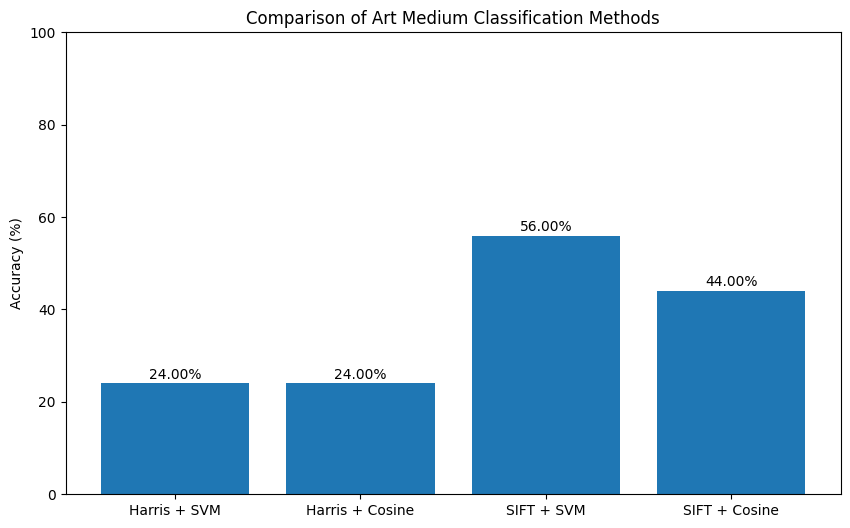

In [28]:
plt.figure(figsize=(10, 6))

labels_graph = [
    "Harris + SVM",
    "Harris + Cosine",
    "SIFT + SVM",
    "SIFT + Cosine"
]

accuracies = [
    harris_svm_accuracy * 100,
    harris_cosine_accuracy * 100,
    sift_svm_accuracy * 100,
    sift_cosine_accuracy * 100
]

plt.bar(
    labels_graph,
    accuracies
)

plt.ylabel("Accuracy (%)")
plt.title("Comparison of Art Medium Classification Methods")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

In [29]:
methods = {
    "Harris + SVM": (
        harris_svm_accuracy,
        harris_svm_predictions
    ),
    "Harris + Cosine": (
        harris_cosine_accuracy,
        harris_cosine_predictions
    ),
    "SIFT + SVM": (
        sift_svm_accuracy,
        sift_svm_predictions
    ),
    "SIFT + Cosine": (
        sift_cosine_accuracy,
        sift_cosine_predictions
    )
}

best_method = max(
    methods,
    key=lambda x: methods[x][0]
)

best_accuracy, best_predictions = methods[best_method]

print("Best Method:", best_method)
print(
    "Best Accuracy:",
    round(best_accuracy * 100, 2),
    "%"
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=classes
    )
)

Best Method: SIFT + SVM
Best Accuracy: 56.0 %

Classification Report:

              precision    recall  f1-score   support

         oil       0.83      1.00      0.91         5
 watercolour       0.00      0.00      0.00         5
         ink       0.80      0.80      0.80         5
      pastel       0.20      0.20      0.20         5
    graphite       0.50      0.80      0.62         5

    accuracy                           0.56        25
   macro avg       0.47      0.56      0.50        25
weighted avg       0.47      0.56      0.50        25



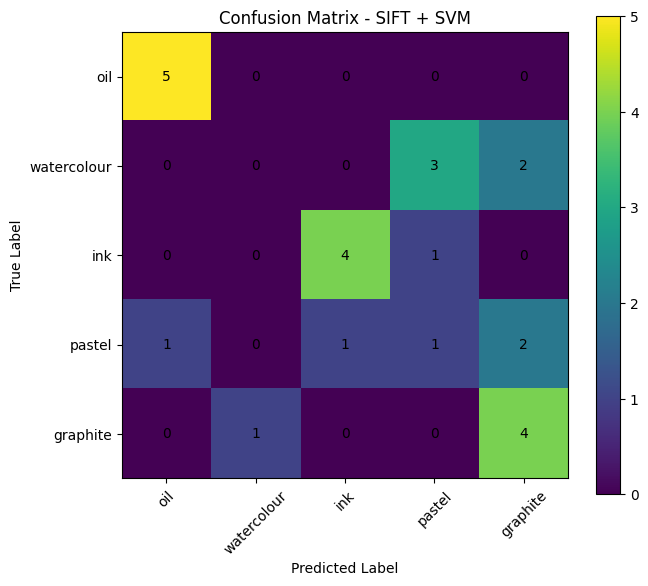

In [30]:
cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(7, 6))

plt.imshow(cm)

plt.xticks(
    range(len(classes)),
    classes,
    rotation=45
)

plt.yticks(
    range(len(classes)),
    classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.title(
    f"Confusion Matrix - {best_method}"
)

for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()